# Toronto Bike Share — Daily cycling patterns, June 2024

Uses the **already routed** GraphHopper OD pairs. No new routing. All plotted routes are modelled, not GPS trajectories. The daily sample excludes same-station trips, non-positive durations and unresolved station coordinates. Maps use identical geographical bounds and a consistent weighting scale.


In [1]:
from pathlib import Path
import sqlite3, json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from matplotlib.collections import LineCollection

PROJECT = Path('/scratch/project_2010417/paper3/toronto-bike-exposure')
DATA = PROJECT / 'data/processed'
OUT = PROJECT / 'outputs/maps/daily'
OUT.mkdir(parents=True, exist_ok=True)

# Read routes once, then reuse geometry for each day.
with sqlite3.connect(DATA / 'full_june_routes.sqlite') as connection:
    saved = pd.read_sql_query('SELECT start_id, end_id, geometry_json FROM routes WHERE geometry_json IS NOT NULL', connection)
saved['start_id'] = saved['start_id'].astype(str)
saved['end_id'] = saved['end_id'].astype(str)
routes = gpd.GeoDataFrame(
    saved[['start_id','end_id']],
    geometry=[shape(json.loads(s)) for s in saved.geometry_json],
    crs='EPSG:4326'
).to_crs(26917)
print(f'{len(routes):,} reconstructed directed OD routes loaded')

# Preserve original trip timestamps; do not infer daily flows from monthly OD counts.
trips = pd.read_parquet(DATA / 'bikeshare_june_2024_validated.parquet',
   columns=['Trip_Id','Start_Time','Start_Station_Id','End_Station_Id', 'Trip_Duration', 'User_Type'])
trips['Start_Time'] = pd.to_datetime(trips['Start_Time'])
trips['date'] = trips['Start_Time'].dt.normalize()
trips['start_id'] = trips['Start_Station_Id'].astype('string')
trips['end_id'] = trips['End_Station_Id'].astype('string')
trips['Trip_Duration'] = pd.to_numeric(trips['Trip_Duration'],errors='coerce')
trips = trips[(trips['date'] >= '2024-06-01') & (trips['date'] <= '2024-06-30')]

# Aggregate daily OD counts and restrict to successfully reconstructed routes.
daily = (trips.loc[trips['Trip_Duration'] > 0]
         .groupby(['date','start_id','end_id'], observed=True)
         .size().rename('n').reset_index())
daily = daily.merge(routes[['start_id','end_id']], on=['start_id','end_id'], how='inner', validate='many_to_one')
print('Days:',daily.date.nunique(), 'Represented routed trips:',f'{daily.n.sum():,}')
print('Original June trip records:',f'{len(trips):,}')

163,026 reconstructed directed OD routes loaded
Days: 30 Represented routed trips: 737,915
Original June trip records: 766,868


## A. Day-to-day trip activity
This includes **only routable OD trips**, not the full raw ridership count. The plotted differences should not yet be attributed to weather or smoke.

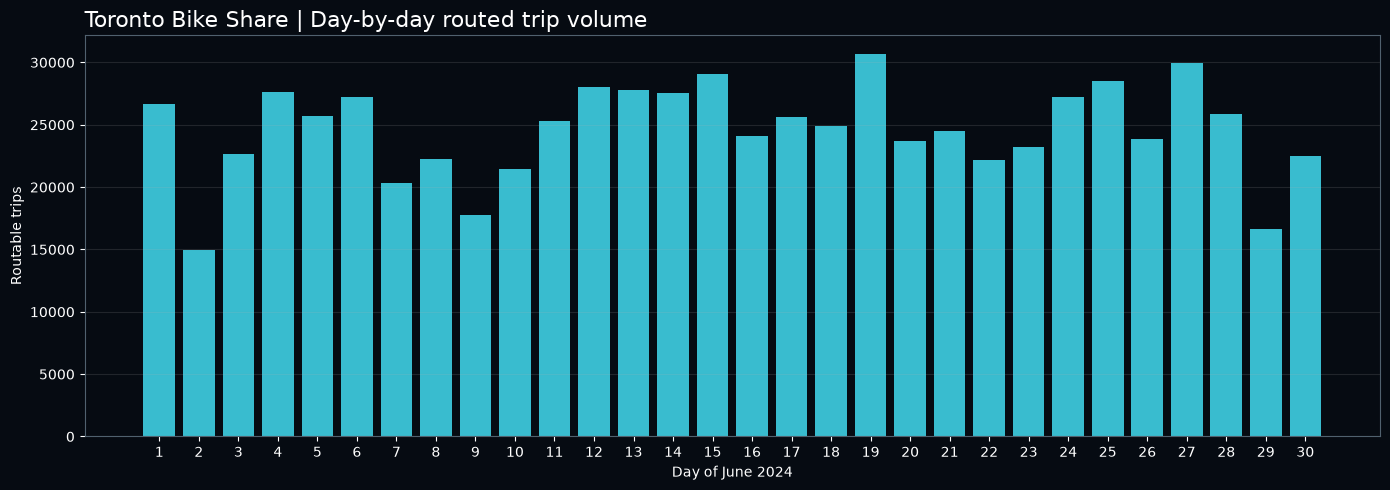

'      date     n   weekday\n2024-06-01 26637  Saturday\n2024-06-02 14987    Sunday\n2024-06-03 22690    Monday\n2024-06-04 27602   Tuesday\n2024-06-05 25699 Wednesday\n2024-06-06 27251  Thursday\n2024-06-07 20335    Friday\n2024-06-08 22272  Saturday\n2024-06-09 17789    Sunday\n2024-06-10 21433    Monday\n2024-06-11 25280   Tuesday\n2024-06-12 28021 Wednesday\n2024-06-13 27791  Thursday\n2024-06-14 27572    Friday\n2024-06-15 29100  Saturday\n2024-06-16 24123    Sunday\n2024-06-17 25656    Monday\n2024-06-18 24887   Tuesday\n2024-06-19 30640 Wednesday\n2024-06-20 23660  Thursday\n2024-06-21 24509    Friday\n2024-06-22 22196  Saturday\n2024-06-23 23203    Sunday\n2024-06-24 27263    Monday\n2024-06-25 28491   Tuesday\n2024-06-26 23892 Wednesday\n2024-06-27 29979  Thursday\n2024-06-28 25838    Friday\n2024-06-29 16659  Saturday\n2024-06-30 22460    Sunday'

In [2]:
counts = daily.groupby('date',as_index=False)['n'].sum()
counts['weekday'] = counts.date.dt.day_name()
fig, ax = plt.subplots(figsize=(14,5), facecolor='#060b12')
ax.set_facecolor('#060b12')
ax.bar(counts.date.dt.day, counts.n, color='#43dcf1', alpha=.85)
ax.set_xticks(range(1,31)); ax.tick_params(colors='white')
ax.set_xlabel('Day of June 2024',color='white');ax.set_ylabel('Routable trips',color='white')
ax.set_title('Toronto Bike Share | Day-by-day routed trip volume',color='white',loc='left',fontsize=16)
for spine in ax.spines.values(): spine.set_color('#50616e')
ax.grid(axis='y',alpha=.16)
fig.tight_layout(); fig.savefig(OUT/'daily_trip_counts.png',dpi=200,facecolor=fig.get_facecolor())
plt.show()
display(counts.assign(date=counts.date.dt.date).to_string(index=False))

## B. Fixed-scale daily neon maps
Brightness and linewidth depend on trips per OD **with the same mathematical scale each day**. Each day's lines follow the precomputed modelled path. The background is deliberately left black; the absence of a line does not mean zero cycling by all Torontonians.

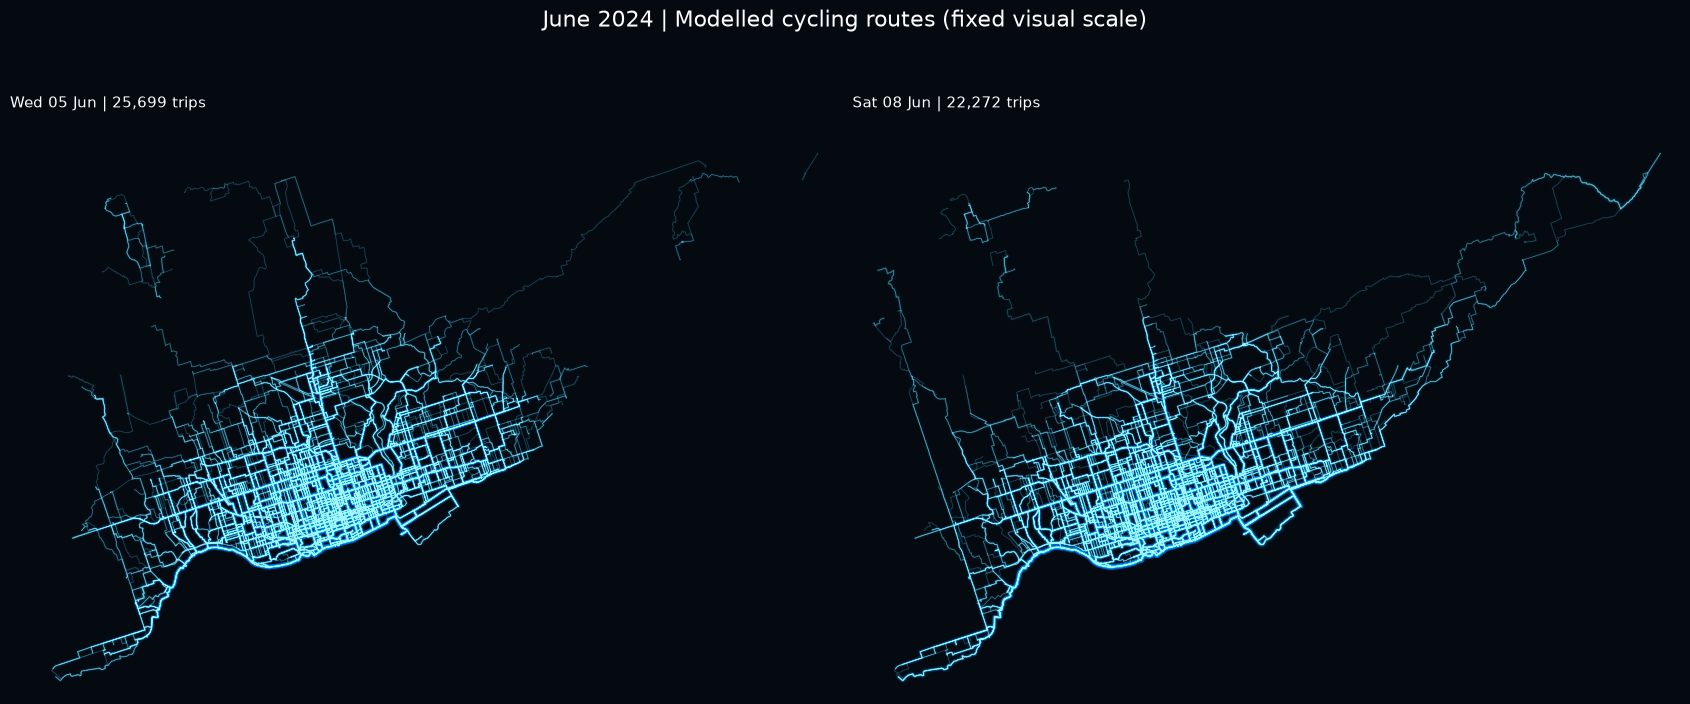

In [4]:
# Reusable, efficient plotting function. Geometry is looked up using a single merge.
route_lines = routes[['start_id','end_id','geometry']].copy()
BOUNDS = routes.total_bounds
pad_x = (BOUNDS[2]-BOUNDS[0])*.025
pad_y = (BOUNDS[3]-BOUNDS[1])*.025

# Upper bound computed across ALL days, not separately for each day.
COMMON_MAX = max(1, int(daily.n.max()))

def draw_day(date, ax, title=None):
    date = pd.Timestamp(date)
    sub = daily.loc[daily.date.eq(date),['start_id','end_id','n']].merge(
        route_lines,on=['start_id','end_id'],how='left',validate='one_to_one')
    sub = gpd.GeoDataFrame(sub, geometry="geometry", crs="EPSG:26917")

    sub = sub.loc[
    sub.geometry.notna()
    & sub.geometry.geom_type.eq("LineString")
    ].copy()
    seg = [np.asarray(g.coords) for g in sub.geometry]
    w = (.20 + 1.05 * np.log1p(sub.n.to_numpy())/np.log1p(COMMON_MAX))
    ax.set_facecolor('#050910')
    for factor, alpha, color in [(6,.018,'#008dff'),(3,.052,'#00c8ff'),(1,.24,'#a8faff')]:
        ax.add_collection(LineCollection(seg,linewidths=w*factor,colors=color,alpha=alpha,rasterized=True))
    ax.set_xlim(BOUNDS[0]-pad_x,BOUNDS[2]+pad_x)
    ax.set_ylim(BOUNDS[1]-pad_y,BOUNDS[3]+pad_y)
    ax.set_aspect('equal');ax.axis('off')
    total = int(sub.n.sum())
    ax.set_title(title or f'{date:%a %d %b} | {total:,} trips',color='white',fontsize=11,loc='left')
    return total

# First compare a weekday with a weekend using identical map scales.
fig,axes = plt.subplots(1,2,figsize=(17,8),facecolor='#050910')
for ax,d in zip(axes,['2024-06-05','2024-06-08']): draw_day(d,ax)
fig.suptitle('June 2024 | Modelled cycling routes (fixed visual scale)',color='white',fontsize=16)
fig.tight_layout();fig.savefig(OUT/'weekday_vs_weekend.png',dpi=180,facecolor=fig.get_facecolor())
plt.show()

## C. Generate the 30 daily frames and an optional GIF
Run this after checking the weekday/weekend comparison. Frame generation draws many geometries and therefore takes more computing time. **Do not put animated GIFs or PNG outputs into GitHub** unless you choose to commit selected small examples.

In [5]:
for d in pd.date_range('2024-06-01','2024-06-30'):
    fig,ax = plt.subplots(figsize=(11,9),facecolor='#050910')
    draw_day(d,ax)
    fig.savefig(OUT / f'route_{d:%Y-%m-%d}.png',dpi=140,facecolor=fig.get_facecolor(),bbox_inches='tight')
    plt.close(fig)
print('Saved 30 daily PNG maps in:',OUT)

Saved 30 daily PNG maps in: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/maps/daily


In [6]:
# Optional animation; run only after creating the 30 PNG frames.
from PIL import Image
frames = []
for d in pd.date_range('2024-06-01','2024-06-30'):
    path = OUT / f'route_{d:%Y-%m-%d}.png'
    with Image.open(path) as im:
        frames.append(im.convert('RGB').copy())
frames[0].save(OUT/'toronto_june_daily_routes.gif',save_all=True,append_images=frames[1:],duration=500,loop=0,optimize=True)
print('Saved:',OUT/'toronto_june_daily_routes.gif')

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/maps/daily/toronto_june_daily_routes.gif


## Research follow-up
Next, compare *matched weekdays* (such as one Wednesday against the other Wednesdays), adjusting for weather, holidays and station availability. For a scientifically interpreted **corridor change map**, aggregate geometries onto street-network edges or onto a fixed raster grid and compute differences against a matched reference. Simple OD-line plotting alone cannot establish cyclist choices or actual traversed links. Current routings also use contemporary OSM and provisional historical station coordinates.